# ✈️ Smart Canopy Lift Inspection System

### Digital Twin Based Multi-Point Canopy Monitoring

**Objective:**  
Automate canopy lift measurement at 12 predefined points,
identify abnormal movement, visualize the canopy using a
Digital Twin, and maintain historical inspection data.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("✅ Libraries loaded successfully")

✅ Libraries loaded successfully


In [ ]:
sensor_points = [f"P{i}" for i in range(1, 13)]

print("Measurement Points:")
print(sensor_points)

Measurement Points:
['P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'P9', 'P10', 'P11', 'P12']


In [ ]:

sensor_points = [f"P{i}" for i in range(1, 13)]

print("Number of measurement points:", len(sensor_points))
print("Measurement points:", sensor_points)

Number of measurement points: 12
Measurement points: ['P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'P9', 'P10', 'P11', 'P12']


In [ ]:


NUM_POINTS = 12
LIMIT_MM = 0.10
DESIRED_RESOLUTION_MM = 0.01

print("Number of measurement points:", NUM_POINTS)
print("Maximum allowable lift:", LIMIT_MM, "mm")
print("Desired measurement resolution:", DESIRED_RESOLUTION_MM, "mm")

Number of measurement points: 12
Maximum allowable lift: 0.1 mm
Desired measurement resolution: 0.01 mm


In [ ]:
# Simulate sensor measurements

np.random.seed(10)

# Initial position of canopy at each point
baseline = np.random.uniform(100, 101, NUM_POINTS)

# Simulated canopy lift after pressurization
canopy_lift = np.random.uniform(0.02, 0.12, NUM_POINTS)

# Create a few abnormal points for demonstration
canopy_lift[2] = 0.13
canopy_lift[8] = 0.16

# Position after pressurization
after_pressure = baseline - canopy_lift

print("Sensor simulation completed!")

Sensor simulation completed!


In [ ]:
# Calculate canopy lift

calculated_lift = baseline - after_pressure

result = pd.DataFrame({
    "Point": sensor_points,
    "Baseline (mm)": np.round(baseline, 3),
    "After Pressure (mm)": np.round(after_pressure, 3),
    "Canopy Lift (mm)": np.round(calculated_lift, 3)
})

result

,Point,Baseline (mm),After Pressure (mm),Canopy Lift (mm)
0,P1,100.771,100.751,0.020
1,P2,100.021,99.950,0.071
2,P3,100.634,100.504,0.130
3,P4,100.749,100.668,0.081
4,P5,100.499,100.406,0.092
5,P6,100.225,100.176,0.049
6,P7,100.198,100.086,0.112
7,P8,100.761,100.669,0.091
8,P9,100.169,100.009,0.160
9,P10,100.088,100.054,0.034


In [ ]:
# Check each measurement against the 0.1 mm limit

result["Status"] = np.where(
    result["Canopy Lift (mm)"] <= LIMIT_MM,
    "🟢 NORMAL",
    "🔴 ABNORMAL"
)

result

,Point,Baseline (mm),After Pressure (mm),Canopy Lift (mm),Status
0,P1,100.771,100.751,0.020,🟢 NORMAL
1,P2,100.021,99.950,0.071,🟢 NORMAL
2,P3,100.634,100.504,0.130,🔴 ABNORMAL
3,P4,100.749,100.668,0.081,🟢 NORMAL
4,P5,100.499,100.406,0.092,🟢 NORMAL
5,P6,100.225,100.176,0.049,🟢 NORMAL
6,P7,100.198,100.086,0.112,🔴 ABNORMAL
7,P8,100.761,100.669,0.091,🟢 NORMAL
8,P9,100.169,100.009,0.160,🔴 ABNORMAL
9,P10,100.088,100.054,0.034,🟢 NORMAL


In [ ]:

abnormal_points = result[result["Status"] == "🔴 ABNORMAL"]
print("========================================")
print("       CANOPY LIFT INSPECTION")
print("========================================")

print("Total measurement points :", NUM_POINTS)
print("Normal points             :", NUM_POINTS - len(abnormal_points))
print("Abnormal points           :", len(abnormal_points))
print("Maximum canopy lift       :",
      f"{result['Canopy Lift (mm)'].max():.3f} mm")

if len(abnormal_points) > 0:
    print("Overall Status            : 🔴 ABNORMAL")
    print("Abnormal locations        :",
          abnormal_points["Point"].tolist())
else:
    print("Overall Status            : 🟢 NORMAL")

print("========================================")

       CANOPY LIFT INSPECTION
Total measurement points : 12
Normal points             : 9
Abnormal points           : 3
Maximum canopy lift       : 0.160 mm
Overall Status            : 🔴 ABNORMAL
Abnormal locations        : ['P3', 'P7', 'P9']


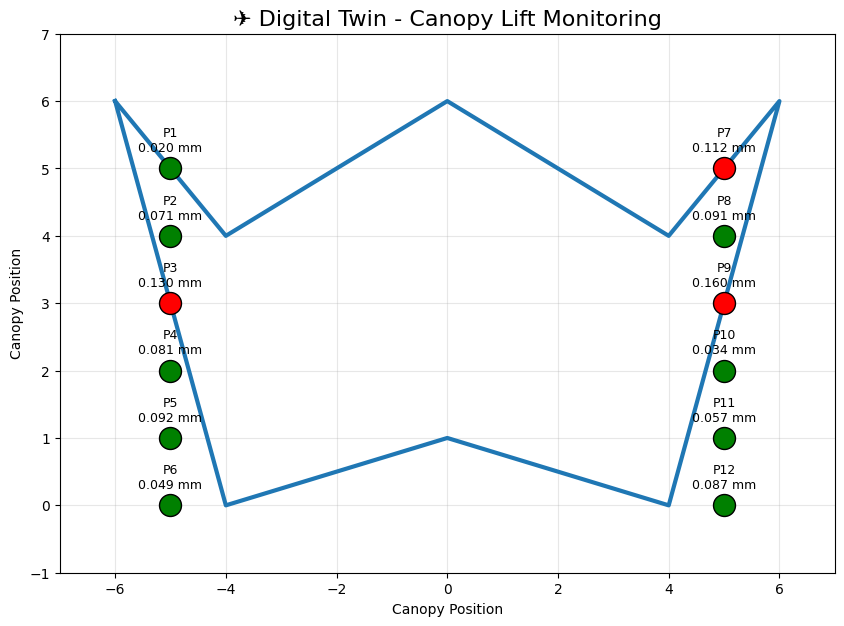

In [ ]:
# Digital Twin - Canopy Visualization

import matplotlib.pyplot as plt

# Position of the 12 measurement points
x = [-5, -5, -5, -5, -5, -5,
      5,  5,  5,  5,  5,  5]

y = [5, 4, 3, 2, 1, 0,
     5, 4, 3, 2, 1, 0]

# Get status from our result table
values = result["Canopy Lift (mm)"].values

plt.figure(figsize=(10, 7))

# Draw canopy outline
canopy_x = [-6, -4, 0, 4, 6, 4, 0, -4, -6]
canopy_y = [6, 4, 6, 4, 6, 0, 1, 0, 6]

plt.plot(canopy_x, canopy_y, linewidth=3)

# Plot measurement points
for i in range(12):

    if values[i] <= LIMIT_MM:
        marker_color = "green"
    else:
        marker_color = "red"

    plt.scatter(
        x[i],
        y[i],
        s=250,
        c=marker_color,
        edgecolors="black",
        zorder=5
    )

    plt.text(
        x[i],
        y[i] + 0.25,
        f"P{i+1}\n{values[i]:.3f} mm",
        ha="center",
        fontsize=9
    )

plt.title("✈️ Digital Twin - Canopy Lift Monitoring", fontsize=16)

plt.xlabel("Canopy Position")
plt.ylabel("Canopy Position")

plt.xlim(-7, 7)
plt.ylim(-1, 7)

plt.grid(True, alpha=0.3)

plt.show()

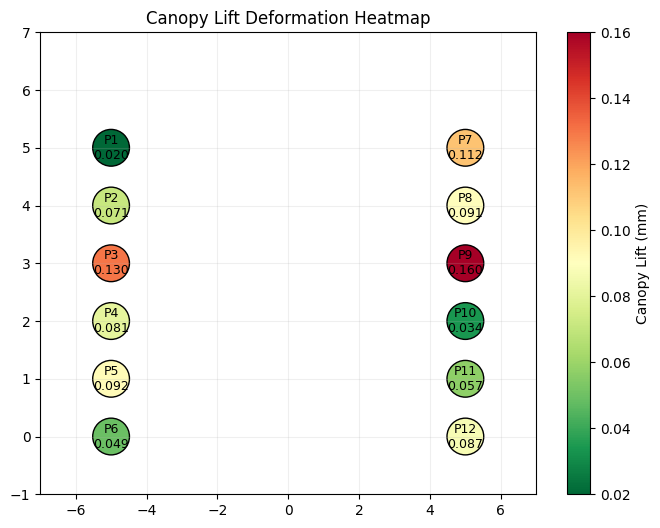

In [ ]:
# Canopy Lift Heatmap

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    x,
    y,
    c=values,
    s=700,
    cmap="RdYlGn_r",
    edgecolors="black"
)

for i in range(12):
    plt.text(
        x[i],
        y[i],
        f"P{i+1}\n{values[i]:.3f}",
        ha="center",
        va="center",
        fontsize=9
    )

plt.colorbar(scatter, label="Canopy Lift (mm)")

plt.title("Canopy Lift Deformation Heatmap")

plt.xlim(-7, 7)
plt.ylim(-1, 7)

plt.grid(alpha=0.2)

plt.show()

In [ ]:
# Historical inspection data

np.random.seed(20)

historical_data = []

for test in range(1, 21):

    for point in sensor_points:

        # Normal historical lift
        lift_value = np.random.uniform(0.02, 0.08)

        # Simulate gradual increase at P3
        if point == "P3":
            lift_value += test * 0.002

        historical_data.append({
            "Test": test,
            "Point": point,
            "Lift (mm)": round(lift_value, 3)
        })

history_df = pd.DataFrame(historical_data)

history_df.head(15)

,Test,Point,Lift (mm)
0,1,P1,0.055
1,1,P2,0.074
2,1,P3,0.075
3,1,P4,0.069
4,1,P5,0.022
5,1,P6,0.062
6,1,P7,0.043
7,1,P8,0.051
8,1,P9,0.059
9,1,P10,0.032


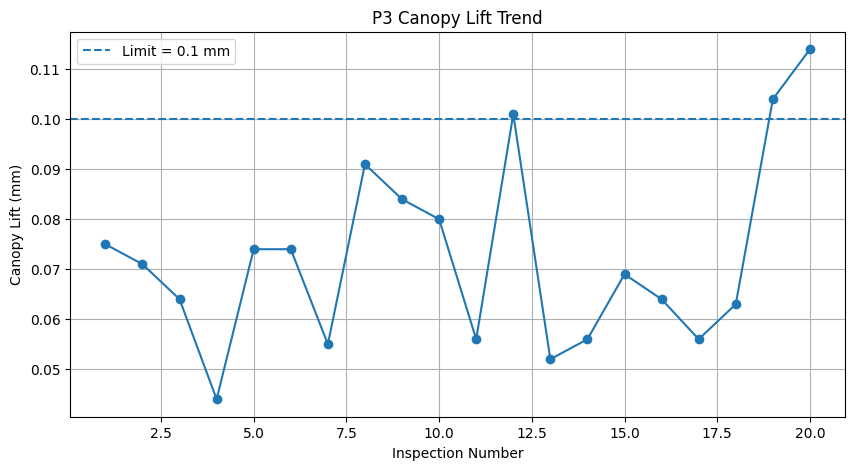

In [ ]:
# Trend analysis for P3

p3_history = history_df[
    history_df["Point"] == "P3"
]

plt.figure(figsize=(10, 5))

plt.plot(
    p3_history["Test"],
    p3_history["Lift (mm)"],
    marker="o"
)

plt.axhline(
    LIMIT_MM,
    linestyle="--",
    label="Limit = 0.1 mm"
)

plt.xlabel("Inspection Number")
plt.ylabel("Canopy Lift (mm)")
plt.title("P3 Canopy Lift Trend")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Automatic trend detection

first_value = p3_history.iloc[0]["Lift (mm)"]
last_value = p3_history.iloc[-1]["Lift (mm)"]

increase = last_value - first_value

print("========================================")
print("          TREND ANALYSIS")
print("========================================")

print(f"P3 First Test Lift : {first_value:.3f} mm")
print(f"P3 Latest Lift     : {last_value:.3f} mm")
print(f"Increase           : {increase:.3f} mm")

if increase > 0.02:
    print("⚠️ WARNING: Increasing canopy lift trend detected!")
else:
    print("🟢 Trend appears stable.")

print("========================================")

          TREND ANALYSIS
P3 First Test Lift : 0.075 mm
P3 Latest Lift     : 0.114 mm
Increase           : 0.039 mm
⚠️ WARNING: Increasing canopy lift trend detected!


In [ ]:
# Canopy Health Score

maximum_lift = result["Canopy Lift (mm)"].max()

# Calculate score relative to the limit
health_score = max(
    0,
    min(100, 100 * (1 - maximum_lift / (LIMIT_MM * 2)))
)

print("========================================")
print("       CANOPY HEALTH SCORE")
print("========================================")
print(f"Health Score : {health_score:.1f} / 100")

if health_score >= 80:
    print("Condition    : 🟢 GOOD")
elif health_score >= 60:
    print("Condition    : 🟡 ATTENTION")
else:
    print("Condition    : 🔴 CRITICAL")

print("========================================")

       CANOPY HEALTH SCORE
Health Score : 20.0 / 100
Condition    : 🔴 CRITICAL


In [ ]:
# Sensor health check

sensor_health = []

for point in sensor_points:

    # Simulated sensor status
    status = "OK"

    sensor_health.append({
        "Sensor": point,
        "Health": status
    })

sensor_health_df = pd.DataFrame(sensor_health)

sensor_health_df

,Sensor,Health
0,P1,OK
1,P2,OK
2,P3,OK
3,P4,OK
4,P5,OK
5,P6,OK
6,P7,OK
7,P8,OK
8,P9,OK
9,P10,OK


In [ ]:
import plotly.graph_objects as go

# Canopy measurement point positions
x_points = [-5, -5, -5, -5, -5, -5,
             5,  5,  5,  5,  5,  5]

y_points = [5, 4, 3, 2, 1, 0,
            5, 4, 3, 2, 1, 0]

# Current lift values
lift_values = result["Canopy Lift (mm)"].values

# Point status
point_status = [
    "NORMAL" if value <= LIMIT_MM else "ABNORMAL"
    for value in lift_values
]

# Green / red point colors
point_colors = [
    "green" if value <= LIMIT_MM else "red"
    for value in lift_values
]

fig = go.Figure()

# Canopy outline
canopy_x = [-6, -4, 0, 4, 6, 4, 0, -4, -6]
canopy_y = [6, 4, 6, 4, 6, 0, 1, 0, 6]

fig.add_trace(
    go.Scatter(
        x=canopy_x,
        y=canopy_y,
        mode="lines",
        line=dict(width=4),
        name="Canopy"
    )
)

# Measurement points
fig.add_trace(
    go.Scatter(
        x=x_points,
        y=y_points,
        mode="markers+text",
        marker=dict(
            size=25,
            color=point_colors,
            line=dict(width=2, color="black")
        ),
        text=[
            f"P{i+1}<br>{lift_values[i]:.3f} mm"
            for i in range(12)
        ],
        textposition="top center",
        hovertext=[
            f"Point: P{i+1}<br>"
            f"Lift: {lift_values[i]:.3f} mm<br>"
            f"Status: {point_status[i]}"
            for i in range(12)
        ],
        hoverinfo="text",
        name="Measurement Points"
    )
)

fig.update_layout(
    title="✈️ Digital Twin — Live Canopy Lift",
    xaxis_title="Canopy Position",
    yaxis_title="Canopy Position",
    width=900,
    height=650,
    template="plotly_white"
)

fig.show()

In [ ]:
from IPython.display import display

selected_point = "P3"

selected_data = result[
    result["Point"] == selected_point
]

print("================================")
print(f"     POINT {selected_point} ANALYSIS")
print("================================")

print(
    "Baseline:",
    selected_data["Baseline (mm)"].values[0],
    "mm"
)

print(
    "After Pressure:",
    selected_data["After Pressure (mm)"].values[0],
    "mm"
)

print(
    "Canopy Lift:",
    selected_data["Canopy Lift (mm)"].values[0],
    "mm"
)

print(
    "Status:",
    selected_data["Status"].values[0]
)

print("================================")

     POINT P3 ANALYSIS
Baseline: 100.634 mm
After Pressure: 100.504 mm
Canopy Lift: 0.13 mm
Status: 🔴 ABNORMAL


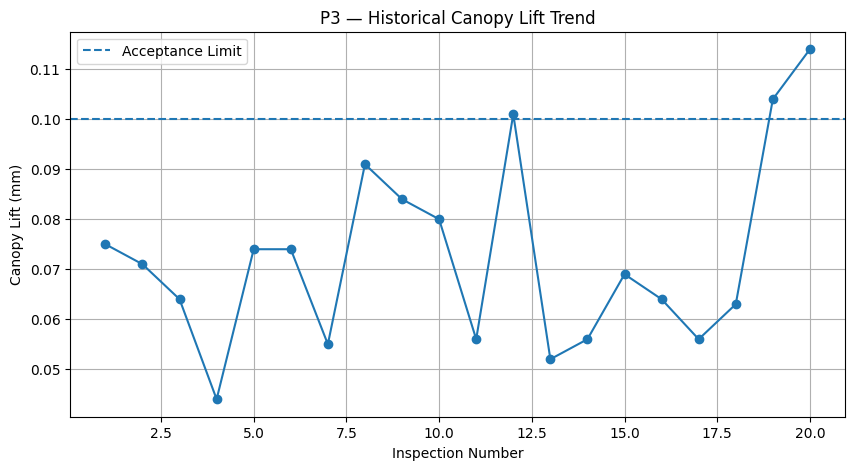

In [ ]:
selected_point = "P3"

selected_history = history_df[
    history_df["Point"] == selected_point
]

plt.figure(figsize=(10, 5))

plt.plot(
    selected_history["Test"],
    selected_history["Lift (mm)"],
    marker="o"
)

plt.axhline(
    LIMIT_MM,
    linestyle="--",
    label="Acceptance Limit"
)

plt.xlabel("Inspection Number")
plt.ylabel("Canopy Lift (mm)")

plt.title(
    f"{selected_point} — Historical Canopy Lift Trend"
)

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Automatic inspection recommendation

abnormal_points = result[
    result["Canopy Lift (mm)"] > LIMIT_MM
]

print("========================================")
print("       AUTOMATED INSPECTION RESULT")
print("========================================")

if len(abnormal_points) == 0:

    print("🟢 STATUS: NORMAL")
    print("No measurement point exceeded the limit.")

else:

    print("🔴 STATUS: ABNORMAL")
    print(
        f"{len(abnormal_points)} point(s) exceeded "
        "the configured acceptance limit."
    )

    print("\nPoints requiring attention:")

    for _, row in abnormal_points.iterrows():

        print(
            f"⚠ {row['Point']} → "
            f"{row['Canopy Lift (mm)']:.3f} mm"
        )

print("========================================")

       AUTOMATED INSPECTION RESULT
🔴 STATUS: ABNORMAL
3 point(s) exceeded the configured acceptance limit.

Points requiring attention:
⚠ P3 → 0.130 mm
⚠ P7 → 0.112 mm
⚠ P9 → 0.160 mm


In [ ]:
def run_canopy_inspection(
    aircraft_id="FA-001",
    test_id="TEST-001"
):

    print("=" * 60)
    print("       ✈️ SMART CANOPY LIFT INSPECTION")
    print("       DIGITAL TWIN MONITORING SYSTEM")
    print("=" * 60)

    print(f"\nAircraft ID : {aircraft_id}")
    print(f"Test ID     : {test_id}")
    print(f"Points      : {NUM_POINTS}")
    print(f"Limit       : {LIMIT_MM:.2f} mm")
    print(f"Resolution  : {DESIRED_RESOLUTION_MM:.2f} mm")

    # --------------------------------------------------
    # 1. Simulate baseline measurement
    # --------------------------------------------------

    np.random.seed()

    baseline = np.random.uniform(
        100,
        101,
        NUM_POINTS
    )

    # --------------------------------------------------
    # 2. Simulate canopy lift
    # --------------------------------------------------

    canopy_lift = np.random.uniform(
        0.02,
        0.09,
        NUM_POINTS
    )

    # Add abnormal points for demonstration
    canopy_lift[2] = 0.13

    after_pressure = baseline - canopy_lift

    # --------------------------------------------------
    # 3. Calculate lift
    # --------------------------------------------------

    calculated_lift = baseline - after_pressure

    # --------------------------------------------------
    # 4. Create result table
    # --------------------------------------------------

    inspection = pd.DataFrame({

        "Point": sensor_points,

        "Baseline (mm)": np.round(
            baseline,
            3
        ),

        "After Pressure (mm)": np.round(
            after_pressure,
            3
        ),

        "Lift (mm)": np.round(
            calculated_lift,
            3
        )
    })

    # --------------------------------------------------
    # 5. Normal / abnormal detection
    # --------------------------------------------------

    inspection["Status"] = np.where(

        inspection["Lift (mm)"] <= LIMIT_MM,

        "🟢 NORMAL",

        "🔴 ABNORMAL"
    )

    # --------------------------------------------------
    # 6. Statistics
    # --------------------------------------------------

    normal_points = sum(
        inspection["Lift (mm)"] <= LIMIT_MM
    )

    abnormal_points = sum(
        inspection["Lift (mm)"] > LIMIT_MM
    )

    maximum_lift = inspection["Lift (mm)"].max()

    # --------------------------------------------------
    # 7. Display results
    # --------------------------------------------------

    display(inspection)

    print("\n" + "=" * 60)
    print("               INSPECTION SUMMARY")
    print("=" * 60)

    print(
        f"Normal Points     : {normal_points} 🟢"
    )

    print(
        f"Abnormal Points   : {abnormal_points} 🔴"
    )

    print(
        f"Maximum Lift      : {maximum_lift:.3f} mm"
    )

    # --------------------------------------------------
    # 8. Overall status
    # --------------------------------------------------

    if abnormal_points == 0:

        print(
            "\nOVERALL STATUS : 🟢 NORMAL"
        )

    else:

        print(
            "\nOVERALL STATUS : 🔴 ABNORMAL"
        )

        print("\nPoints requiring attention:")

        for _, row in inspection[
            inspection["Lift (mm)"] > LIMIT_MM
        ].iterrows():

            print(
                f"  ⚠ {row['Point']} → "
                f"{row['Lift (mm)']:.3f} mm"
            )

    print("=" * 60)

    return inspection

In [ ]:
final_result = run_canopy_inspection(
    aircraft_id="FIGHTER-001",
    test_id="TEST-001"
)

       ✈️ SMART CANOPY LIFT INSPECTION
       DIGITAL TWIN MONITORING SYSTEM

Aircraft ID : FIGHTER-001
Test ID     : TEST-001
Points      : 12
Limit       : 0.10 mm
Resolution  : 0.01 mm


,Point,Baseline (mm),After Pressure (mm),Lift (mm),Status
0,P1,100.194,100.110,0.084,🟢 NORMAL
1,P2,100.964,100.915,0.048,🟢 NORMAL
2,P3,100.008,99.878,0.130,🔴 ABNORMAL
3,P4,100.768,100.708,0.060,🟢 NORMAL
4,P5,100.092,100.024,0.068,🟢 NORMAL
5,P6,100.632,100.544,0.088,🟢 NORMAL
6,P7,100.389,100.335,0.054,🟢 NORMAL
7,P8,100.200,100.148,0.052,🟢 NORMAL
8,P9,100.360,100.286,0.073,🟢 NORMAL
9,P10,100.215,100.167,0.048,🟢 NORMAL



               INSPECTION SUMMARY
Normal Points     : 11 🟢
Abnormal Points   : 1 🔴
Maximum Lift      : 0.130 mm

OVERALL STATUS : 🔴 ABNORMAL

Points requiring attention:
  ⚠ P3 → 0.130 mm


In [ ]:
# Final Digital Twin Visualization

values = final_result["Lift (mm)"].values

point_colors = [
    "green" if value <= LIMIT_MM else "red"
    for value in values
]

fig = go.Figure()

# Canopy outline
fig.add_trace(
    go.Scatter(
        x=canopy_x,
        y=canopy_y,
        mode="lines",
        line=dict(width=5),
        name="Canopy"
    )
)

# Sensor points
fig.add_trace(
    go.Scatter(
        x=x_points,
        y=y_points,
        mode="markers+text",

        marker=dict(
            size=30,
            color=point_colors,
            line=dict(
                width=2,
                color="black"
            )
        ),

        text=[
            f"P{i+1}<br>{values[i]:.3f} mm"
            for i in range(12)
        ],

        textposition="top center",

        hovertext=[
            f"<b>P{i+1}</b><br>"
            f"Lift: {values[i]:.3f} mm<br>"
            f"Limit: {LIMIT_MM:.2f} mm<br>"
            f"Status: "
            f"{'NORMAL' if values[i] <= LIMIT_MM else 'ABNORMAL'}"
            for i in range(12)
        ],

        hoverinfo="text",

        name="Sensors"
    )
)

fig.update_layout(

    title=(
        f"✈️ Digital Twin — "
        f"{'NORMAL' if max(values) <= LIMIT_MM else 'ABNORMAL'}"
    ),

    xaxis_title="Canopy Width",

    yaxis_title="Canopy Position",

    width=950,

    height=650,

    template="plotly_white"
)

fig.show()

In [ ]:
import sqlite3

# Create SQLite database
conn = sqlite3.connect("canopy_inspection.db")

print("✅ SQL database connected")

✅ SQL database connected


In [ ]:
cursor = conn.cursor()

cursor.execute("""
CREATE TABLE IF NOT EXISTS inspections (
    aircraft_id TEXT,
    test_id TEXT,
    point TEXT,
    baseline_mm REAL,
    after_pressure_mm REAL,
    lift_mm REAL,
    status TEXT
)
""")

conn.commit()

print("✅ Inspection table created")

✅ Inspection table created


In [ ]:
for _, row in final_result.iterrows():

    cursor.execute("""
    INSERT INTO inspections
    (aircraft_id, test_id, point, baseline_mm,
     after_pressure_mm, lift_mm, status)

    VALUES (?, ?, ?, ?, ?, ?, ?)
    """, (
        "FIGHTER-001",
        "TEST-001",
        row["Point"],
        row["Baseline (mm)"],
        row["After Pressure (mm)"],
        row["Lift (mm)"],
        row["Status"]
    ))

conn.commit()

print("✅ Inspection data stored in SQL")

✅ Inspection data stored in SQL


In [ ]:
sql_query = """
SELECT
    point,
    lift_mm,
    status
FROM inspections
WHERE test_id = 'TEST-001'
ORDER BY point
"""

sql_result = pd.read_sql_query(sql_query, conn)

sql_result

,point,lift_mm,status
0,P1,0.084,🟢 NORMAL
1,P10,0.048,🟢 NORMAL
2,P11,0.078,🟢 NORMAL
3,P12,0.034,🟢 NORMAL
4,P2,0.048,🟢 NORMAL
5,P3,0.130,🔴 ABNORMAL
6,P4,0.060,🟢 NORMAL
7,P5,0.068,🟢 NORMAL
8,P6,0.088,🟢 NORMAL
9,P7,0.054,🟢 NORMAL


In [ ]:
import plotly.express as px

fig = px.bar(
    sql_result,
    x="point",
    y="lift_mm",
    title="Canopy Lift by Measurement Point",
    labels={
        "point": "Measurement Point",
        "lift_mm": "Canopy Lift (mm)"
    }
)

fig.show()

In [ ]:
abnormal_query = """
SELECT
    aircraft_id,
    test_id,
    point,
    lift_mm,
    status
FROM inspections
WHERE status = '🔴 ABNORMAL'
"""

abnormal_result = pd.read_sql_query(
    abnormal_query,
    conn
)

abnormal_result

,aircraft_id,test_id,point,lift_mm,status
0,FIGHTER-001,TEST-001,P3,0.13,🔴 ABNORMAL


In [ ]:
max_lift_query = """
SELECT
    point,
    MAX(lift_mm) AS maximum_lift
FROM inspections
GROUP BY point
ORDER BY maximum_lift DESC
"""

max_lift_result = pd.read_sql_query(
    max_lift_query,
    conn
)

max_lift_result

,point,maximum_lift
0,P3,0.130
1,P6,0.088
2,P1,0.084
3,P11,0.078
4,P9,0.073
5,P5,0.068
6,P4,0.060
7,P7,0.054
8,P8,0.052
9,P2,0.048


In [ ]:
# Official measurement requirements

NUM_POINTS = 12

MEASUREMENT_LEAST_COUNT_MM = 0.10
DESIRED_RESOLUTION_MM = 0.01
DEVIATION_LIMIT_MM = 1.50

print("=" * 50)
print("       CANOPY LIFT REQUIREMENTS")
print("=" * 50)

print("Measurement points       :", NUM_POINTS)
print("Required least count    :", MEASUREMENT_LEAST_COUNT_MM, "mm")
print("Desired resolution      :", DESIRED_RESOLUTION_MM, "mm")
print("Deviation criterion     :", DEVIATION_LIMIT_MM, "mm")

print("=" * 50)

       CANOPY LIFT REQUIREMENTS
Measurement points       : 12
Required least count    : 0.1 mm
Desired resolution      : 0.01 mm
Deviation criterion     : 1.5 mm


In [ ]:
import sqlite3

conn = sqlite3.connect("canopy_dashboard.db")
cursor = conn.cursor()

cursor.execute("""
CREATE TABLE IF NOT EXISTS inspections (
    aircraft_id TEXT,
    test_id TEXT,
    point TEXT,
    baseline_mm REAL,
    after_pressure_mm REAL,
    lift_mm REAL,
    status TEXT
)
""")

conn.commit()

print("✅ SQL database connected")
print("✅ Inspections table created")

✅ SQL database connected
✅ Inspections table created


In [ ]:
# Store the current inspection results in SQL

cursor.execute("DELETE FROM inspections")

for _, row in final_result.iterrows():
    cursor.execute("""
    INSERT INTO inspections
    (aircraft_id, test_id, point, baseline_mm,
     after_pressure_mm, lift_mm, status)
    VALUES (?, ?, ?, ?, ?, ?, ?)
    """, (
        "FIGHTER-001",
        "TEST-001",
        row["Point"],
        row["Baseline (mm)"],
        row["After Pressure (mm)"],
        row["Lift (mm)"],
        row["Status"]
    ))

conn.commit()

print("✅ 12 inspection records stored in SQL")

✅ 12 inspection records stored in SQL


In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd

# Read inspection data from SQL
dashboard_data = pd.read_sql_query("""
    SELECT aircraft_id, test_id, point, lift_mm, status
    FROM inspections
    ORDER BY point
""", conn)

# KPI values
aircraft_id = dashboard_data["aircraft_id"].iloc[0]
test_id = dashboard_data["test_id"].iloc[0]

total_points = len(dashboard_data)
normal_points = (dashboard_data["status"] == "🟢 NORMAL").sum()
abnormal_points = (dashboard_data["status"] == "🔴 ABNORMAL").sum()
max_lift = dashboard_data["lift_mm"].max()

overall_status = "🔴 ABNORMAL" if abnormal_points > 0 else "🟢 NORMAL"

# Create dashboard
fig = make_subplots(
    rows=2,
    cols=2,
    specs=[
        [{"type": "indicator"}, {"type": "indicator"}],
        [{"type": "xy"}, {"type": "xy"}]
    ],
    subplot_titles=(
        "Maximum Canopy Lift",
        "Abnormal Measurement Points",
        "12-Point Canopy Lift",
        "Digital Twin"
    ),
    vertical_spacing=0.15,
    horizontal_spacing=0.10
)

# KPI 1
fig.add_trace(
    go.Indicator(
        mode="number",
        value=max_lift,
        number={"suffix": " mm", "valueformat": ".3f"},
        title={"text": "Maximum Lift"}
    ),
    row=1, col=1
)

# KPI 2
fig.add_trace(
    go.Indicator(
        mode="number",
        value=abnormal_points,
        number={"suffix": " points"},
        title={"text": "Abnormal Points"}
    ),
    row=1, col=2
)

# 12-point bar chart
bar_colors = [
    "red" if s == "🔴 ABNORMAL" else "green"
    for s in dashboard_data["status"]
]

fig.add_trace(
    go.Bar(
        x=dashboard_data["point"],
        y=dashboard_data["lift_mm"],
        marker_color=bar_colors,
        text=dashboard_data["lift_mm"].round(3),
        textposition="outside",
        name="Canopy Lift"
    ),
    row=2, col=1
)

# Digital Twin coordinates
x_dt = [-5,-5,-5,-5,-5,-5,5,5,5,5,5,5]
y_dt = [5,4,3,2,1,0,5,4,3,2,1,0]

dt_colors = [
    "red" if s == "🔴 ABNORMAL" else "green"
    for s in dashboard_data["status"]
]

# Canopy outline
canopy_x = [-6,-4,0,4,6,4,0,-4,-6]
canopy_y = [6,4,6,4,6,0,1,0,6]

fig.add_trace(
    go.Scatter(
        x=canopy_x,
        y=canopy_y,
        mode="lines",
        line=dict(width=4),
        name="Canopy"
    ),
    row=2, col=2
)

# Measurement points
fig.add_trace(
    go.Scatter(
        x=x_dt,
        y=y_dt,
        mode="markers+text",
        marker=dict(
            size=22,
            color=dt_colors,
            line=dict(width=2, color="black")
        ),
        text=[
            f"{p}<br>{v:.3f} mm"
            for p, v in zip(
                dashboard_data["point"],
                dashboard_data["lift_mm"]
            )
        ],
        textposition="top center",
        hovertemplate=[
            f"<b>{p}</b><br>"
            f"Lift: {v:.3f} mm<br>"
            f"Status: {s}<extra></extra>"
            for p, v, s in zip(
                dashboard_data["point"],
                dashboard_data["lift_mm"],
                dashboard_data["status"]
            )
        ],
        name="Sensors"
    ),
    row=2, col=2
)

# Layout
fig.update_layout(
    title={
        "text": (
            f"✈️ SMART CANOPY LIFT INSPECTION DASHBOARD"
            f"<br><sup>{aircraft_id} | {test_id} | Overall: {overall_status}</sup>"
        ),
        "x": 0.5
    },
    height=900,
    width=1200,
    showlegend=False,
    template="plotly_white"
)

fig.update_xaxes(title_text="Measurement Point", row=2, col=1)
fig.update_yaxes(title_text="Lift (mm)", row=2, col=1)

fig.update_xaxes(
    title_text="Canopy Width",
    range=[-7, 7],
    row=2, col=2
)

fig.update_yaxes(
    title_text="Canopy Position",
    range=[-1, 7],
    row=2, col=2
)

fig.show()

print("=" * 60)
print("                 INSPECTION DASHBOARD")
print("=" * 60)
print(f"Aircraft ID       : {aircraft_id}")
print(f"Test ID           : {test_id}")
print(f"Measurement Points: {total_points}")
print(f"Normal Points     : {normal_points}")
print(f"Abnormal Points   : {abnormal_points}")
print(f"Maximum Lift      : {max_lift:.3f} mm")
print(f"Overall Status    : {overall_status}")
print("=" * 60)

                 INSPECTION DASHBOARD
Aircraft ID       : FIGHTER-001
Test ID           : TEST-001
Measurement Points: 12
Normal Points     : 11
Abnormal Points   : 1
Maximum Lift      : 0.130 mm
Overall Status    : 🔴 ABNORMAL
